# Praktikum Uji Validitas dan Reliabilitas
Nama: Berlindi Achica Tama

NIM: 2455301038

Kelas: 3TIB

## 1. Unggah CSV respons


In [1]:
from google.colab import files
uploaded = files.upload()
nama_file = list(uploaded.keys())[0]
print("File terbaca:", nama_file)


Saving Form responses.csv to Form responses.csv
File terbaca: Form responses.csv


## 2. Impor pustaka dan persiapan


In [2]:
import csv
import json
import re
import sys
from collections import Counter, OrderedDict
from pathlib import Path

import numpy as np
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

FILE = Path(nama_file)
OUT = Path('output_uji')
OUT.mkdir(exist_ok=True)
SKALA = {'Sangat Tidak Setuju (STS)':1, 'Tidak Setuju (TS)':2, 'Netral (N)':3,
         'Setuju (S)':4, 'Sangat Setuju (SS)':5}
LABEL = ['STS', 'TS', 'N', 'S', 'SS']



## 3. Baca data, filter kelas, dan kelompokkan dimensi


In [3]:
with FILE.open(encoding='utf-8-sig', newline='') as f:
    semua = list(csv.DictReader(f))
if not semua:
    raise ValueError('File CSV tidak memiliki respons.')
respon = [r for r in semua if r.get('Kelas','').strip().upper() == '3 TI A']
if not respon:
    raise ValueError('Tidak ada data 3 TI A.')

kolom = list(semua[0].keys())
dimensi = OrderedDict()
for nama_kolom in kolom:
    m = re.match(r'^\s*(.*?)\s*\[', nama_kolom)
    if not m:
        continue
    isi = [r[nama_kolom].strip() for r in respon]
    if not set(isi).issubset(SKALA):
        raise ValueError(f'Jawaban tidak dikenali pada item {nama_kolom!r}: {set(isi)-set(SKALA)}')
    dimensi.setdefault(m.group(1).strip(), []).append(nama_kolom)


print("Jumlah respons kelas 3 TI A:",len(respon))
print("Jumlah dimensi:",len(dimensi))
print("Jumlah butir:",sum(map(len,dimensi.values())))


Jumlah respons kelas 3 TI A: 39
Jumlah dimensi: 5
Jumlah butir: 29


## 4. Fungsi validitas dan reliabilitas


In [4]:
n = len(respon)
df = n-2
krit = stats.t.ppf(0.975, df)
r_tabel = float(krit/np.sqrt(df+krit**2))

def alpha(x):
    k = x.shape[1]
    if k<2: return float('nan')
    v_total = x.sum(axis=1).var(ddof=1)
    if v_total == 0: return float('nan')
    return float(k/(k-1)*(1-x.var(axis=0,ddof=1).sum()/v_total))

def kategori(a):
    if not np.isfinite(a): return 'Tidak dapat dihitung'
    if a>=0.9: return 'Sangat baik'
    if a>=0.8: return 'Baik'
    if a>=0.7: return 'Reliabel'
    return 'Tidak reliabel'

hasil = {'semua_kelas':dict(Counter(r.get('Kelas','').strip() for r in semua)),
         'n_seluruh':len(semua), 'n':n, 'df':df, 'r_tabel':r_tabel,
         'jumlah_dimensi':len(dimensi), 'jumlah_butir':sum(map(len,dimensi.values())),
         'jumlah_dikeluarkan':0, 'dimensi':[]}
validitas_rows=[]
reliabilitas_rows=[]
ringkasan_rows=[]



## 5. Jalankan pengujian dan buat grafik


In [5]:
for indeks, (nama, daftar) in enumerate(dimensi.items(),1):
    x = np.array([[SKALA[r[k].strip()] for k in daftar] for r in respon], dtype=float)
    total = x.sum(axis=1)
    a=alpha(x)
    res={'nama':nama,'nomor':indeks,'jumlah_butir':len(daftar),
         'alpha':a,'kategori':kategori(a),'butir':[],
         'skala_counts': [int((x==v).sum()) for v in range(1,6)],
         'mean':float(x.mean()),
         'std_dimensi':float(total.std(ddof=1)),
         'std_rerata':float(x.mean(axis=1).std(ddof=1)),
         'skewness':float(stats.skew(total,bias=False)),
         'kurtosis':float(stats.kurtosis(total,bias=False)),
         'n':n,'min_total':int(min(total)),'max_total':int(max(total)),
         'avg_total':float(total.mean())}
    for i,k in enumerate(daftar):
        r,p = stats.pearsonr(x[:,i],total)
        cr,cp=stats.pearsonr(x[:,i],total-x[:,i])
        a_del=alpha(np.delete(x,i,axis=1)) if len(daftar)>2 else float('nan')
        item={'kode': f'D{indeks}B{i+1}', 'pertanyaan': k.split('[',1)[1].rstrip(']').strip(),
              'r_hitung':float(r),'p_value':float(p),'corrected_r':float(cr),
              'alpha_jika_dihapus':a_del,'status': 'Valid' if r>r_tabel else 'Tidak valid',
              'corrected_ge_030':bool(cr>=.30), 'alpha_meningkat_jika_dihapus':bool(a_del>a+1e-10)}
        res['butir'].append(item)
        validitas_rows.append([nama, item['kode'], k, round(item['r_hitung'],6), round(r_tabel,6),
                              round(item['corrected_r'],6),round(item['p_value'],6),
                              item['status'],round(a_del,6) if np.isfinite(a_del) else None])
    res['n_valid']=sum(t['status']=='Valid' for t in res['butir'])
    res['n_corrected']=sum(t['corrected_ge_030'] for t in res['butir'])
    hasil['dimensi'].append(res)
    reliabilitas_rows.append([nama,len(daftar),round(a,6),res['kategori'],res['n_valid'],len(daftar)-res['n_valid']])
    ringkasan_rows.append([nama,n,len(daftar),round(res['mean'],6),round(res['std_dimensi'],6),
                           round(res['skewness'],6),round(res['kurtosis'],6)]+res['skala_counts'])
    fig, ax = plt.subplots(figsize=(7.2,3.5))
    counts=np.array(res['skala_counts'])
    bars=ax.bar(LABEL, counts, color=['#D9E6F2','#94B6D2','#527FA8','#255778','#0D3A62'])
    for bar,c in zip(bars,counts):
        ax.annotate(f'{c}\n({c/counts.sum():.1%})', (bar.get_x()+bar.get_width()/2,c),
                    ha='center',va='bottom',fontsize=8)
    ax.set_ylim(0,max(counts)*1.23)
    ax.set_ylabel('Frekuensi jawaban')
    ax.set_xlabel('Kategori skala Likert')
    ax.set_title(f'Dimensi {indeks}: komposisi jawaban (n={n})',fontsize=11)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='y', alpha=0.2)
    fig.tight_layout()
    fname=f'grafik_dimensi_{indeks}.png'
    fig.savefig(OUT/fname,dpi=170,bbox_inches='tight')
    plt.close(fig)
    res['grafik']=fname



## 6. Simpan seluruh hasil pengujian


In [6]:
with (OUT/'hasil_analisis.json').open('w',encoding='utf-8') as f:
    json.dump(hasil,f,ensure_ascii=False,indent=2)
with (OUT/'validitas.csv').open('w',encoding='utf-8-sig',newline='') as f:
    w=csv.writer(f);w.writerow(['Dimensi','Kode','Pernyataan','r_hitung','r_tabel','Corrected_r','p_value','Keputusan','Alpha_jika_dihapus']);w.writerows(validitas_rows)
with (OUT/'reliabilitas.csv').open('w',encoding='utf-8-sig',newline='') as f:
    w=csv.writer(f);w.writerow(['Dimensi','Jumlah_butir','Cronbach_alpha','Kategori','Butir_valid','Butir_tidak_valid']);w.writerows(reliabilitas_rows)
with (OUT/'deskriptif.csv').open('w',encoding='utf-8-sig',newline='') as f:
    w=csv.writer(f);w.writerow(['Dimensi','N','Jumlah_butir','Mean_item','SD_total','Skewness_total','Kurtosis_excess_total','STS','TS','Netr','S','SS']);w.writerows(ringkasan_rows)
# Data terfilter tanpa identitas, untuk audit perhitungan
with (OUT/'data_3_TI_A_anonim.csv').open('w',encoding='utf-8-sig',newline='') as f:
    w=csv.writer(f);w.writerow(['ID anonim']+[f'D{di}B{j}' for di,cols in enumerate(dimensi.values(),1) for j in range(1,len(cols)+1)])
    for idx,r in enumerate(respon,1):
        w.writerow([f'R{idx:02d}']+[SKALA[r[c].strip()] for cols in dimensi.values() for c in cols])



In [7]:
print(f'Semua respons: {len(semua)}; kelas 3 TI A: {n}; {len(dimensi)} dimensi; {hasil["jumlah_butir"]} butir; r tabel: {r_tabel:.6f}')
for d in hasil['dimensi']:
    print(f'{d["nomor"]}. {d["nama"]}: {d["jumlah_butir"]} butir, alpha={d["alpha"]:.4f} ({d["kategori"]}), valid {d["n_valid"]}/{d["jumlah_butir"]}, corrected>=.30 {d["n_corrected"]}, mean={d["mean"]:.3f}, SDtotal={d["std_dimensi"]:.3f}, skew={d["skewness"]:.3f}, kurt={d["kurtosis"]:.3f}')
    for q in d['butir']:
        print(f'  {q["kode"]}: r={q["r_hitung"]:.3f}, corrected={q["corrected_r"]:.3f}, alpha_del={q["alpha_jika_dihapus"]:.3f}, {q["status"]}')


Semua respons: 181; kelas 3 TI A: 39; 5 dimensi; 29 butir; r tabel: 0.316032
1. Penggunaan AI pada tugas atau projek kuliah: 7 butir, alpha=0.3700 (Tidak reliabel), valid 5/7, corrected>=.30 2, mean=3.897, SDtotal=3.017, skew=-0.425, kurt=1.612
  D1B1: r=0.525, corrected=0.277, alpha_del=0.275, Valid
  D1B2: r=0.269, corrected=0.105, alpha_del=0.362, Tidak valid
  D1B3: r=0.643, corrected=0.379, alpha_del=0.193, Valid
  D1B4: r=0.669, corrected=0.397, alpha_del=0.171, Valid
  D1B5: r=0.515, corrected=0.126, alpha_del=0.367, Valid
  D1B6: r=0.455, corrected=0.139, alpha_del=0.348, Valid
  D1B7: r=0.016, corrected=-0.247, alpha_del=0.513, Tidak valid
2. Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir, alpha=0.3746 (Tidak reliabel), valid 5/7, corrected>=.30 3, mean=3.132, SDtotal=3.737, skew=0.248, kurt=-0.752
  D2B1: r=0.538, corrected=0.228, alpha_del=0.299, Valid
  D2B2: r=0.645, corrected=0.377, alpha_del=0.200, Valid
  D2B3: r=0.495, corrected=0.213, alpha_del=

## 7. Lihat grafik dan unduh hasil


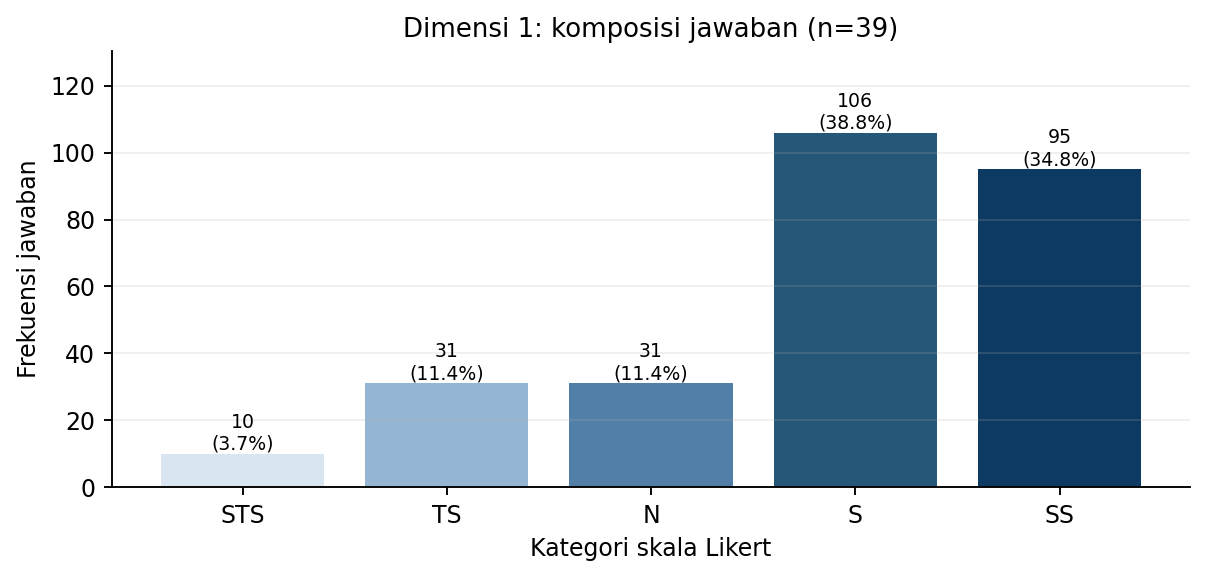

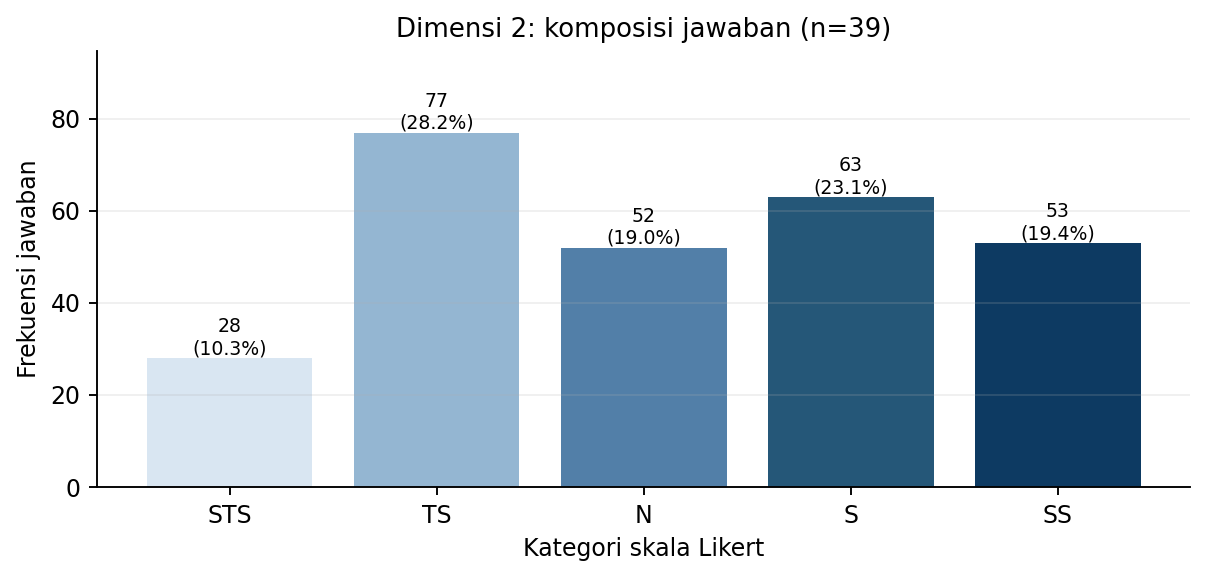

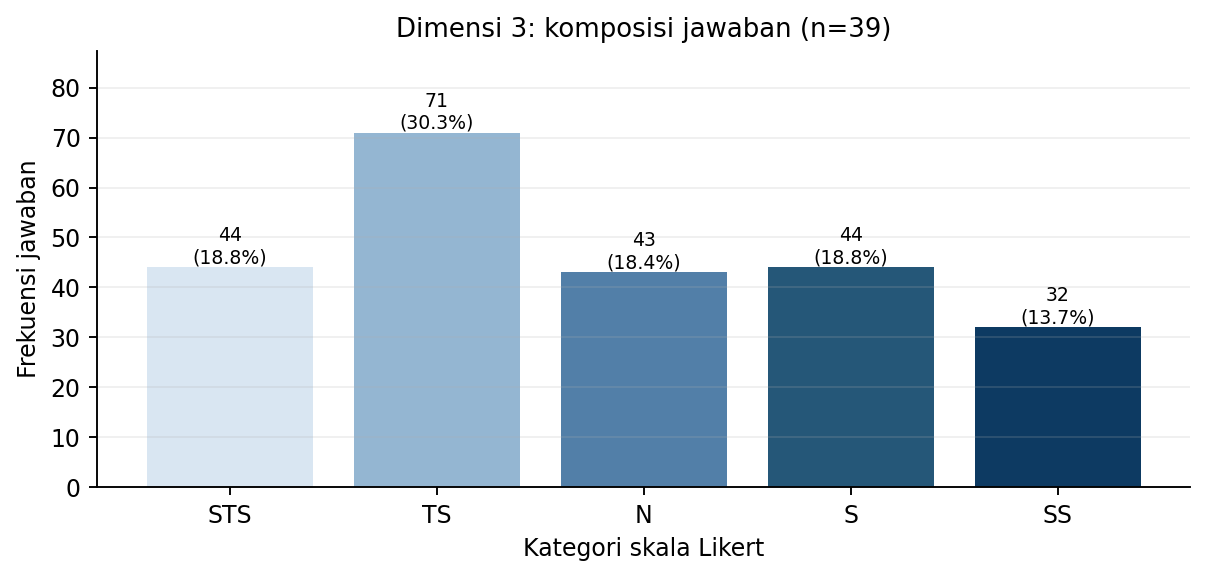

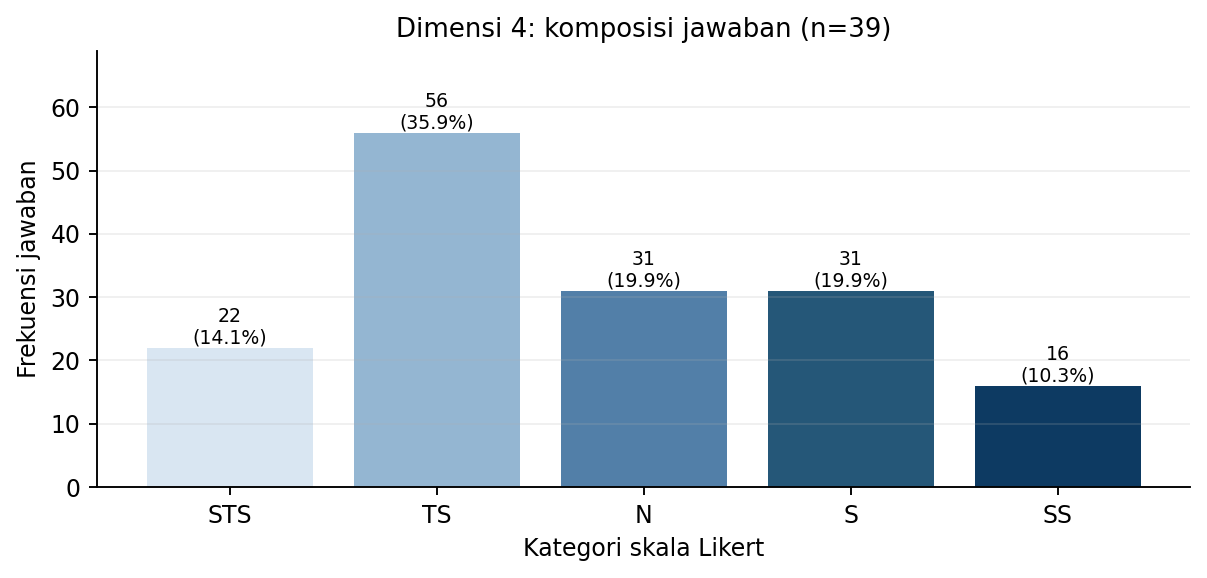

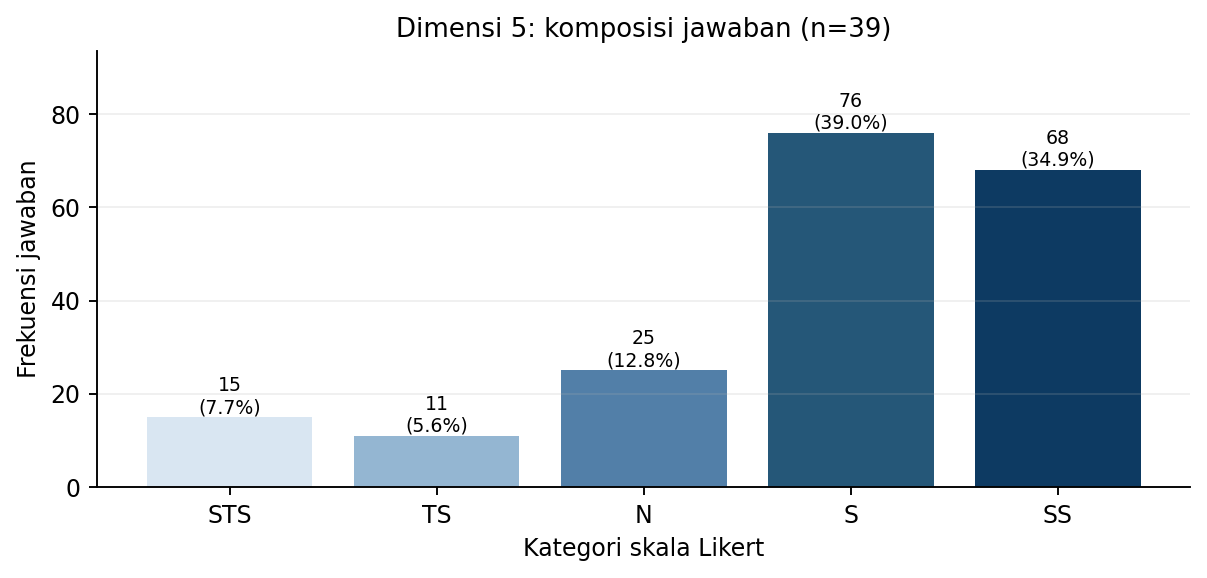

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from IPython.display import Image, display
for j in range(1,len(dimensi)+1):
    display(Image(filename=f"output_uji/grafik_dimensi_{j}.png", width=620))
import shutil
shutil.make_archive("hasil_uji_3_TI_A", "zip", "output_uji")
files.download("hasil_uji_3_TI_A.zip")
